# Lab 1 — Intro to Behavioral TV Data
Name: [Alexander Zavadskyi] | Group: [KM-41]

This notebook analyzes one month (October 2024) of synthetic people-meter panel data for 10 US networks.
All numbers are projected to the US universe using respondent weights.


## Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
from collections import defaultdict

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

# Convert timestamps
for df in [programs, viewings]:
    df['start_ts'] = pd.to_datetime(df['start_ts'])
    df['end_ts'] = pd.to_datetime(df['end_ts'])
daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.date
programs['broadcast_date'] = pd.to_datetime(programs['broadcast_date']).dt.date

print("Data loaded successfully")
print(f"Programs: {programs.shape}, Viewings: {viewings.shape}, Daily weights: {daily_weights.shape}")


/opt/homebrew/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data loaded successfully
Programs: (5841, 15), Viewings: (1001885, 9), Daily weights: (407561, 4)


## Task 1.1 — Panel and universe

In [2]:
print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['program_name'].nunique())
print("Networks:", programs['network_code'].nunique())

hh_in_panel = daily_weights[daily_weights['resp_type']=='H']['respondent_id'].nunique()
persons_in_panel = daily_weights[daily_weights['resp_type'].isin(['R','L'])]['respondent_id'].nunique()
print("Households in panel:", hh_in_panel)
print("Persons in panel:", persons_in_panel)

print("Households in-tab, average day:", round(daily_weights[daily_weights['resp_type']=='H'].groupby('broadcast_date')['respondent_id'].nunique().mean(), 1))
print("Persons in-tab, average day:", round(daily_weights[daily_weights['resp_type'].isin(['R','L'])].groupby('broadcast_date')['respondent_id'].nunique().mean(), 1))

print("US TV households represented, average day (M):", round(daily_weights[daily_weights['resp_type']=='H'].groupby('broadcast_date')['weight'].sum().mean() / 1e6, 2))
print("US persons represented, average day (M):", round(daily_weights[daily_weights['resp_type'].isin(['R','L'])].groupby('broadcast_date')['weight'].sum().mean() / 1e6, 2))


Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


**Answer:**  
The panel covers 5,841 telecasts of 246 distinct programs across 10 networks.  
4,254 households and 10,210 persons (R+L) were in-tab at least once.  
`viewer_attributes` lists more respondents (~14,472) because it includes the full attribute history, not only those active in October.  
On an average day ~3,879 households and ~9,269 persons are in-tab, representing the full US universes of 125.8M TV households and 317.3M persons 2+.

## Task 1.2 — Average audience by hour of day

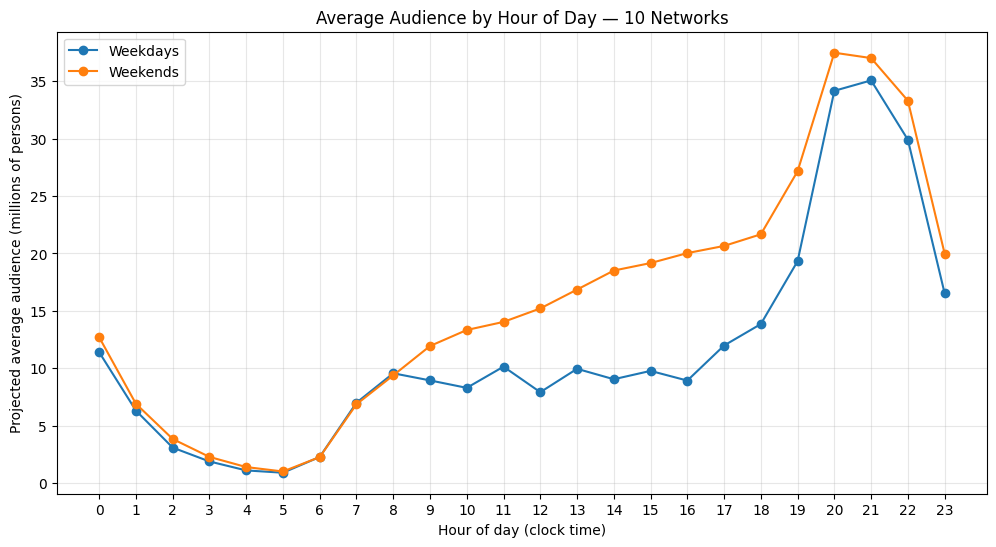

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [3]:
def expand_to_hourly_weighted(viewings_df):
    records = []
    for start, end, weight in zip(viewings_df['start_ts'], viewings_df['end_ts'], viewings_df['weight']):
        current = start
        while current < end:
            hour_floor = current.replace(minute=0, second=0, microsecond=0)
            hour_ceil = hour_floor + timedelta(hours=1)
            overlap_end = min(end, hour_ceil)
            mins = (overlap_end - current).total_seconds() / 60.0
            if mins > 0.001:
                hour = hour_floor.hour
                bd = (hour_floor - timedelta(days=1)).date() if hour < 6 else hour_floor.date()
                records.append((hour, bd, mins * weight))
            current = overlap_end
    return pd.DataFrame(records, columns=['hour', 'broadcast_date', 'weighted_minutes'])

person_v = viewings[viewings['resp_type'].isin(['R','L'])].copy()
hourly = expand_to_hourly_weighted(person_v)
hourly['broadcast_date'] = pd.to_datetime(hourly['broadcast_date'])
hourly['is_weekend'] = hourly['broadcast_date'].dt.dayofweek >= 5

all_days = pd.to_datetime(daily_weights['broadcast_date'].unique())
n_wd = sum(d.dayofweek < 5 for d in all_days)
n_we = sum(d.dayofweek >= 5 for d in all_days)

agg = hourly.groupby(['hour', 'is_weekend'])['weighted_minutes'].sum().reset_index()
agg['avg_audience_m'] = agg.apply(
    lambda r: r['weighted_minutes'] / 60 / (n_we if r['is_weekend'] else n_wd) / 1e6, axis=1)

plt.figure(figsize=(12,6))
for we, lab, col in [(False, 'Weekdays', 'C0'), (True, 'Weekends', 'C1')]:
    sub = agg[agg['is_weekend']==we].sort_values('hour')
    plt.plot(sub['hour'], sub['avg_audience_m'], marker='o', label=lab, color=col)
plt.xlabel('Hour of day (clock time)')
plt.ylabel('Projected average audience (millions of persons)')
plt.title('Average Audience by Hour of Day — 10 Networks')
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

wd_peak = agg[~agg['is_weekend']].loc[agg[~agg['is_weekend']]['avg_audience_m'].idxmax()]
we_peak = agg[agg['is_weekend']].loc[agg[agg['is_weekend']]['avg_audience_m'].idxmax()]
print("Peak hour, weekdays:", int(wd_peak['hour']))
print("Peak hour, weekends:", int(we_peak['hour']))


**Answer:**  
Weekdays peak at 21:00 (~35.1M), weekends at 20:00 (~37.5M).  
Weekends show higher daytime and early-evening audiences and a slightly earlier prime-time peak, reflecting different viewing habits (more leisure time during the day).

## Task 1.3 — Session length

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


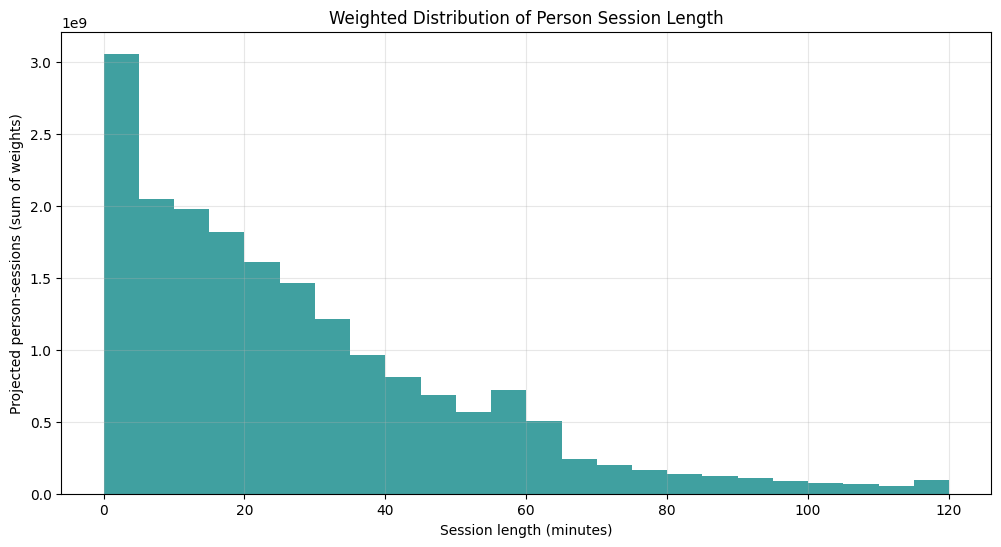

In [4]:
pv = viewings[viewings['resp_type'].isin(['R','L'])].copy()
pv['duration_min'] = (pv['end_ts'] - pv['start_ts']).dt.total_seconds() / 60

weighted_mean = np.average(pv['duration_min'], weights=pv['weight'])
sorted_pv = pv.sort_values('duration_min')
cumw = sorted_pv['weight'].cumsum()
med_idx = (cumw >= sorted_pv['weight'].sum()/2).idxmax()
weighted_median = sorted_pv.loc[med_idx, 'duration_min']

print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))

plt.figure(figsize=(12,6))
bins = np.arange(0, 121, 5)
plt.hist(pv['duration_min'], bins=bins, weights=pv['weight'], color='teal', alpha=0.75)
plt.xlabel('Session length (minutes)')
plt.ylabel('Projected person-sessions (sum of weights)')
plt.title('Weighted Distribution of Person Session Length')
plt.grid(True, alpha=0.3)
plt.show()


**Answer:**  
Weighted mean is 29.4 min, median is 21.0 min.  
The distribution is right-skewed (many short sessions, a long tail of multi-hour viewing), so the mean is pulled up by rare long sessions.  
For a client deck the median is the better “typical session length” summary; the mean is useful when calculating total viewing time.

## Task 2 — Program reach curve

 n       date  hh_rating  p2_rating  audience_m
 1 2024-10-01        3.5        1.7        5.28
 2 2024-10-02        3.1        1.5        4.68
 3 2024-10-03        3.0        1.5        4.68
 4 2024-10-04        3.0        1.5        4.81
 5 2024-10-07        3.1        1.5        4.83
 6 2024-10-08        3.2        1.6        4.97
 7 2024-10-09        3.0        1.5        4.70
 8 2024-10-10        3.4        1.6        5.13
 9 2024-10-11        3.1        1.5        4.69
10 2024-10-14        2.9        1.4        4.59
11 2024-10-15        3.1        1.5        4.82
12 2024-10-16        3.0        1.5        4.62
13 2024-10-17        3.4        1.7        5.30
14 2024-10-18        2.7        1.3        4.23
15 2024-10-21        3.1        1.5        4.89
16 2024-10-22        3.6        1.8        5.70
17 2024-10-23        3.4        1.6        5.21
18 2024-10-24        3.2        1.5        4.91
19 2024-10-25        3.4        1.7        5.27
20 2024-10-28        3.2        1.6     

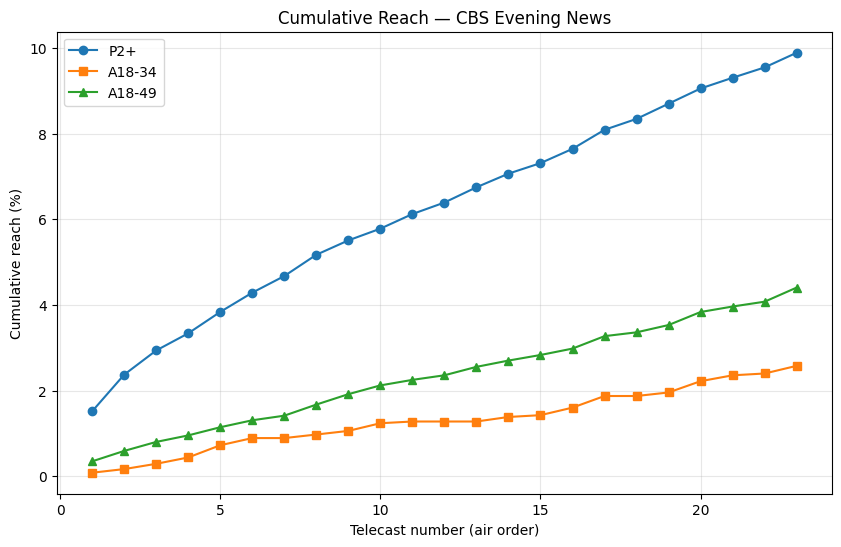

In [5]:
cen = programs[(programs['program_name'].str.contains('Evening News', case=False, na=False)) & 
                (programs['network_code']=='CBS')].sort_values('start_ts')

age = viewer_attributes[viewer_attributes['attr_id']==300][['respondent_id','value']].rename(columns={'value':'age'})
demo = age.copy()

def get_watchers(tele, viewings):
    sess = viewings[(viewings['network_code']==tele['network_code']) &
                    (viewings['start_ts'] < tele['end_ts']) &
                    (viewings['end_ts'] > tele['start_ts'])].copy()
    sess['overlap'] = (sess['end_ts'].clip(upper=tele['end_ts']) - sess['start_ts'].clip(lower=tele['start_ts'])).dt.total_seconds()/60
    return sess[sess['overlap'] >= 1]

person_dw = daily_weights[daily_weights['resp_type'].isin(['R','L'])]
monthly_w = person_dw.groupby('respondent_id')['weight'].mean()

results = []
all_watchers = set()
reach_rows = []

for i, (_, tele) in enumerate(cen.iterrows()):
    wdf = get_watchers(tele, viewings)
    bd = tele['broadcast_date']
    
    # HH rating
    hh_w = set(wdf[wdf['resp_type']=='H']['respondent_id'])
    hh_tab = daily_weights[(daily_weights['broadcast_date']==bd) & (daily_weights['resp_type']=='H')]
    hh_rating = hh_tab[hh_tab['respondent_id'].isin(hh_w)]['weight'].sum() / hh_tab['weight'].sum() * 100
    
    # P2+
    p_w = set(wdf[wdf['resp_type'].isin(['R','L'])]['respondent_id'])
    p_tab = daily_weights[(daily_weights['broadcast_date']==bd) & (daily_weights['resp_type'].isin(['R','L']))]
    p_sum = p_tab[p_tab['respondent_id'].isin(p_w)]['weight'].sum()
    p_rating = p_sum / p_tab['weight'].sum() * 100
    p_aud = p_sum / 1e6
    
    results.append({'n':i+1, 'date':bd, 'hh_rating':round(hh_rating,1), 
                    'p2_rating':round(p_rating,1), 'audience_m':round(p_aud,2)})
    
    all_watchers.update(p_w)
    r_p2 = monthly_w[monthly_w.index.isin(all_watchers)].sum() / monthly_w.sum() * 100
    young = set(demo[(demo['age']>=18)&(demo['age']<=34)]['respondent_id'])
    a49 = set(demo[(demo['age']>=18)&(demo['age']<=49)]['respondent_id'])
    r_a34 = monthly_w[monthly_w.index.isin(all_watchers & young)].sum() / monthly_w[monthly_w.index.isin(young)].sum() * 100
    r_a49 = monthly_w[monthly_w.index.isin(all_watchers & a49)].sum() / monthly_w[monthly_w.index.isin(a49)].sum() * 100
    reach_rows.append({'n':i+1, 'P2+':r_p2, 'A18-34':r_a34, 'A18-49':r_a49})

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False))
print("Telecasts of the program:", len(cen))
print("Average household rating (%):", round(res_df['hh_rating'].mean(),1))
print("Average P2+ rating (%):", round(res_df['p2_rating'].mean(),1))
print("Average projected audience (M):", round(res_df['audience_m'].mean(),2))

reach_df = pd.DataFrame(reach_rows)
print("Final reach P2+ (%):", round(reach_df['P2+'].iloc[-1],1))
print("Final reach A18-34 (%):", round(reach_df['A18-34'].iloc[-1],1))
print("Final reach A18-49 (%):", round(reach_df['A18-49'].iloc[-1],1))

plt.figure(figsize=(10,6))
plt.plot(reach_df['n'], reach_df['P2+'], marker='o', label='P2+')
plt.plot(reach_df['n'], reach_df['A18-34'], marker='s', label='A18-34')
plt.plot(reach_df['n'], reach_df['A18-49'], marker='^', label='A18-49')
plt.xlabel('Telecast number (air order)')
plt.ylabel('Cumulative reach (%)')
plt.title('Cumulative Reach — CBS Evening News')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Answer:**  
Each telecast has a roughly stable rating (~3.2% HH, ~1.6% P2+), yet cumulative reach keeps growing because new people tune in on different days (the audience is not the same set of loyal viewers every night).  
The program reaches P2+ best (final ~9.9%), then A18-49 (~4.4%), and A18-34 least (~2.6%). This matches the known profile of network evening news: it is watched predominantly by older adults.

## Task 3 — Program frequency

Projected viewers (M): 30.8
Average frequency (weighted): 3.6
Median frequency (weighted): 1


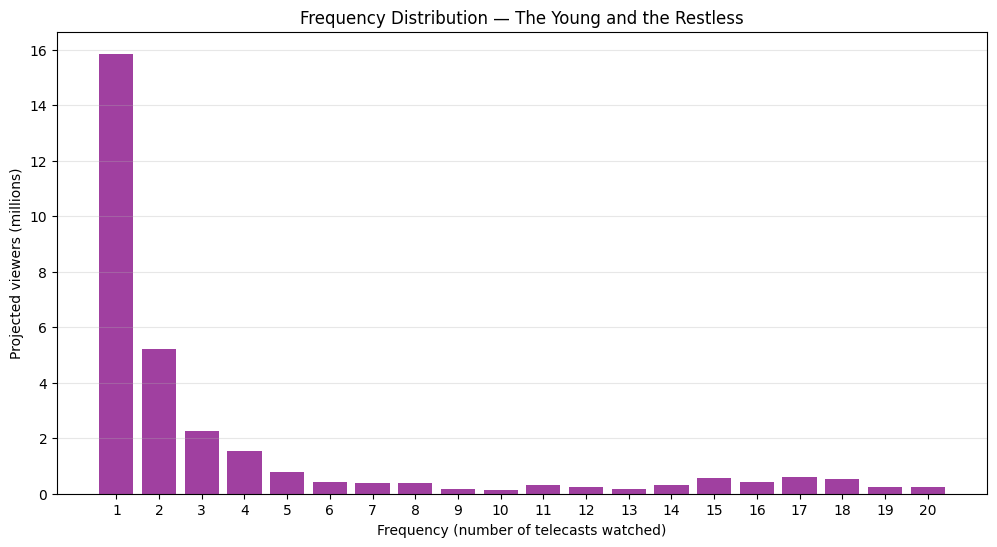

Share of views from the most loyal viewers: 0.704


In [6]:
yatr = programs[(programs['program_name'].str.contains('Young and the Restless', case=False, na=False)) & 
                 (programs['network_code']=='CBS')].sort_values('start_ts')

def get_person_watchers(tele, viewings):
    sess = viewings[(viewings['network_code']==tele['network_code']) &
                    (viewings['resp_type'].isin(['R','L'])) &
                    (viewings['start_ts'] < tele['end_ts']) &
                    (viewings['end_ts'] > tele['start_ts'])].copy()
    sess['overlap'] = (sess['end_ts'].clip(upper=tele['end_ts']) - sess['start_ts'].clip(lower=tele['start_ts'])).dt.total_seconds()/60
    return set(sess[sess['overlap'] >= 1]['respondent_id'])

freq = defaultdict(int)
for _, tele in yatr.iterrows():
    for w in get_person_watchers(tele, viewings):
        freq[w] += 1

freq_s = pd.Series(freq)
person_dw = daily_weights[daily_weights['resp_type'].isin(['R','L'])]
monthly_w = person_dw.groupby('respondent_id')['weight'].mean()

freq_df = pd.DataFrame({'freq': freq_s, 'weight': monthly_w}).dropna()
print("Projected viewers (M):", round(freq_df['weight'].sum()/1e6, 2))

w_avg = np.average(freq_df['freq'], weights=freq_df['weight'])
sorted_f = freq_df.sort_values('freq')
cum = sorted_f['weight'].cumsum()
med = sorted_f.loc[(cum >= sorted_f['weight'].sum()/2).idxmax(), 'freq']
print("Average frequency (weighted):", round(w_avg, 1))
print("Median frequency (weighted):", int(med))

dist = freq_df.groupby('freq')['weight'].sum() / 1e6
plt.figure(figsize=(12,6))
plt.bar(dist.index, dist.values, color='purple', alpha=0.75)
plt.xlabel('Frequency (number of telecasts watched)')
plt.ylabel('Projected viewers (millions)')
plt.title('Frequency Distribution — The Young and the Restless')
plt.xticks(range(1, int(dist.index.max())+1))
plt.grid(True, alpha=0.3, axis='y')
plt.show()

# 80th percentile (weighted)
p80_idx = (cum >= sorted_f['weight'].sum()*0.8).idxmax()
p80 = sorted_f.loc[p80_idx, 'freq']
loyal = freq_df[freq_df['freq'] >= p80]
share = (loyal['freq']*loyal['weight']).sum() / (freq_df['freq']*freq_df['weight']).sum()
print("Share of views from the most loyal viewers:", round(share, 3))


**Answer:**  
Projected viewers ≈ 30.8M, weighted average frequency ≈ 3.6, median = 1.  
The distribution is heavily skewed: most people watch only 1–2 episodes, while a small loyal core watches many.  
The most loyal viewers (frequency ≥ weighted 80th percentile = 4) account for ~70% of all projected views.  
The average frequency is therefore not a fair summary of “typical” behaviour — the median (1) or the full distribution is more honest (“the average can lie”).

## Task 4 — Networks by age and gender

In [7]:
age = viewer_attributes[viewer_attributes['attr_id']==300][['respondent_id','value']].rename(columns={'value':'age'})
sex = viewer_attributes[viewer_attributes['attr_id'].isin([201,202])][['respondent_id','attr_id']]
sex['sex'] = sex['attr_id'].map({201:'M', 202:'W'})
demo = age.merge(sex[['respondent_id','sex']], on='respondent_id')

pv = viewings[viewings['resp_type'].isin(['R','L'])].copy()
pv['duration_min'] = (pv['end_ts'] - pv['start_ts']).dt.total_seconds() / 60
pv = pv.merge(demo, on='respondent_id', how='left')

def audience(row):
    if pd.isna(row.age) or pd.isna(row.sex): return None
    if 18 <= row.age <= 34: return f"{row.sex}18-34"
    if 35 <= row.age <= 54: return f"{row.sex}35-54"
    if row.age >= 55: return f"{row.sex}55+"
    return None

pv['audience'] = pv.apply(audience, axis=1)
pv['w_min'] = pv['duration_min'] * pv['weight']

agg = pv.dropna(subset=['audience']).groupby(['network_code','audience'])['w_min'].sum().reset_index()

for aud in ['M18-34','W18-34','M35-54','W35-54','M55+','W55+']:
    print(f"\nTop 5 for {aud}:")
    top = agg[agg['audience']==aud].nlargest(5, 'w_min')
    for _, r in top.iterrows():
        print(f"  {r['network_code']}: {r['w_min']/1e9:.2f} billion weighted minutes")

pv['is_young'] = pv['age'].between(18,34)
stats = pv.groupby('network_code').apply(
    lambda g: pd.Series({
        'young_share_w': g.loc[g['is_young'],'w_min'].sum() / g['w_min'].sum(),
        'young_share_raw': g.loc[g['is_young'],'duration_min'].sum() / g['duration_min'].sum()
    })
).round(3)

print("\n18-34 share of minutes (weighted | raw):")
print(stats.sort_values('young_share_w', ascending=False))

print("Youngest network:", stats['young_share_w'].idxmax())
print("Oldest network:", stats['young_share_w'].idxmin())



Top 5 for M18-34:
  FOX: 4.39 billion weighted minutes
  NBC: 3.91 billion weighted minutes
  CBS: 3.04 billion weighted minutes
  ABC: 3.01 billion weighted minutes
  FX: 1.47 billion weighted minutes

Top 5 for W18-34:
  FOX: 4.57 billion weighted minutes
  NBC: 4.53 billion weighted minutes
  ABC: 3.50 billion weighted minutes
  CBS: 2.81 billion weighted minutes
  FX: 1.38 billion weighted minutes

Top 5 for M35-54:
  FOX: 12.80 billion weighted minutes
  NBC: 10.99 billion weighted minutes
  ABC: 9.04 billion weighted minutes
  CBS: 8.13 billion weighted minutes
  FX: 2.37 billion weighted minutes

Top 5 for W35-54:
  NBC: 11.64 billion weighted minutes
  FOX: 11.16 billion weighted minutes
  ABC: 9.44 billion weighted minutes
  CBS: 8.16 billion weighted minutes
  HGTV: 3.05 billion weighted minutes

Top 5 for M55+:
  CBS: 38.27 billion weighted minutes
  NBC: 34.27 billion weighted minutes
  FOX: 30.88 billion weighted minutes
  ABC: 30.79 billion weighted minutes
  FNC: 27.90 

/var/folders/x_/z1f2tt5s0xl8s0lsrk71vdhm0000gn/T/ipykernel_10892/3309970221.py:29: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stats = pv.groupby('network_code').apply(


**Answer:**  
Weighted vs raw: the ranking is similar, but weighted shares are slightly higher for younger-skewing networks (FX, Bravo) and slightly lower for older ones (FNC).  
This tells us the panel slightly under-represents young adults relative to the universe (their weights are higher).  
Reporting raw panel numbers would understate the true size of younger audiences and overstate older ones, leading to incorrect media planning recommendations.

**Bonus answer:**  
If selling ads on the oldest network (Fox News Channel), pitch it as the most efficient way to reach high-income, high-influence adults 55+ who control a disproportionate share of discretionary spending. Complement with digital/social extensions or younger-skewing dayparts if the advertiser also needs some 18-34 exposure, but the core value is unparalleled concentration in the 55+ segment that many competitors under-deliver.